<!-- m6:clase=5;checkpoints=7;preguntas=3 -->
# Módulo 6 · Clase 5 — Deep learning básico · Anomalías y segmentación · IA en producción
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · martes 17-11-2026 · 18:30–21:30

**Cómo trabajar este cuaderno**
1. Ejecute las celdas en orden con `Shift + Enter`. Las celdas **➕ Ejemplo adicional** son opcionales.
2. En cada **✏️ Checkpoint** complete los `___` y ejecute: si está bien, aparece ✅ y un código personal.
3. Responda las **💬 Preguntas** en 2 o 3 líneas. Las secciones 5.2 y 5.5 son teóricas (diapositivas).
4. Al final: **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta `talleres/clase5.ipynb` → mensaje `Clase 5`.

> Datos: app de pagos móviles **PagoYa** (ficticia, simulada con fines didácticos). Las secciones 5.3 y 5.4 son la base del problema **segmentación** del proyecto final.

## 0. Preparación y registro (Checkpoint 0)

In [1]:
import os, math, time, warnings, importlib, urllib.request
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore'); os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, silhouette_score
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
plt.rcParams['figure.figsize'] = (10, 3.4)
print('Listo · curso', curso.VERSION, '· TensorFlow', tf.__version__)

Listo · curso m6-2026.11 · TensorFlow 2.21.0


### ✏️ Checkpoint 0 · ⏱ 2 min
Registre su nombre como **'Apellido Nombre'** e indique la **clase 5**.

In [2]:
curso.registrar('Verdezoto Marcelo', clase=5)          # ✏️ su apellido y nombre, y el número de esta clase

Estudiante registrado: Verdezoto Marcelo
Clase 5
✅ Checkpoint 0 correcto · código K0-C37C


In [3]:
df = curso.cargar_pagoya_limpio()                           # mismas transacciones de las clases anteriores
df['ratio'] = df['monto'] / df['ingreso_mensual']
cols = curso.X_COLS + ['ratio']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)
escalador = StandardScaler().fit(X_tr)
X_tr_esc, X_val_esc, X_test_esc = escalador.transform(X_tr), escalador.transform(X_val), escalador.transform(X_test)
print('Entrenamiento:', X_tr_esc.shape, '· validación:', X_val_esc.shape, '· prueba:', X_test_esc.shape)

Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 8.44%
Entrenamiento: (1677, 9) · validación: (420, 9) · prueba: (899, 9)


---
## 5.1 Deep learning básico: cómo se entrena y cómo se evita el sobreajuste
| Concepto | Qué es |
|---|---|
| **Época** | Una pasada completa por todos los datos de entrenamiento |
| **Batch** | Cuántos ejemplos se procesan antes de actualizar los pesos |
| **Iteración** | Una actualización de pesos (un batch). Iteraciones por época = ⌈n / batch⌉ |
| **Learning rate** | Tamaño de cada ajuste de los pesos: muy alto no converge, muy bajo aprende lento |
| **Optimizador** | Algoritmo que mueve los pesos para bajar la pérdida (SGD, Adam, AdamW) |

### ✏️ Checkpoint 1 · ⏱ 3 min
Con **batch = 32**, ¿cuántas **iteraciones** (actualizaciones de pesos) hace la red en **una época** sobre `X_tr_esc`?

In [4]:
batch = 32
iteraciones = math.ceil(len(X_tr_esc) / batch)
print(f'{len(X_tr_esc)} ejemplos / {batch} = {iteraciones} iteraciones por época')
curso.checkpoint(1, iteraciones)

1677 ejemplos / 32 = 53 iteraciones por época
✅ Checkpoint 1 correcto · código K1-1F17


### Sobreajuste: una red demasiado grande y sin freno
Entrenamos una red grande (128-128-64 neuronas, ≈ 26 000 parámetros) durante 120 épocas **sin regularización**. Observe las dos curvas de pérdida.

Parámetros: 26,113 · tiempo 21.9 s


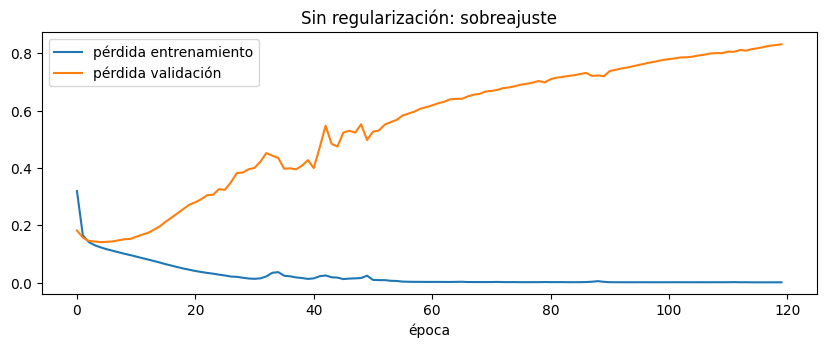

AUC prueba (red grande): 0.903


In [5]:
keras.utils.set_random_seed(42)
grande = keras.Sequential([keras.Input(shape=(len(cols),)),
                           keras.layers.Dense(128, activation='relu'),
                           keras.layers.Dense(128, activation='relu'),
                           keras.layers.Dense(64, activation='relu'),
                           keras.layers.Dense(1, activation='sigmoid')])
grande.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=[keras.metrics.AUC(name='auc')])
t0 = time.perf_counter()
h_grande = grande.fit(X_tr_esc, y_tr, validation_data=(X_val_esc, y_val), epochs=120, batch_size=32, verbose=0)
print(f'Parámetros: {grande.count_params():,} · tiempo {time.perf_counter() - t0:.1f} s')
plt.plot(h_grande.history['loss'], label='pérdida entrenamiento'); plt.plot(h_grande.history['val_loss'], label='pérdida validación')
plt.xlabel('época'); plt.legend(); plt.title('Sin regularización: sobreajuste'); plt.show()
print(f"AUC prueba (red grande): {roc_auc_score(y_test, grande.predict(X_test_esc, verbose=0).ravel()):.3f}")

### Regularización: L2, Dropout, normalización por lotes y early stopping
| Técnica | Qué hace |
|---|---|
| **L2** (`kernel_regularizer`) | Penaliza pesos grandes en la pérdida (como ridge) |
| **Dropout** | Apaga al azar un % de neuronas en cada batch: la red no depende de unas pocas |
| **BatchNormalization** | Normaliza las activaciones de cada batch: entrenamiento más estable |
| **EarlyStopping** | Se detiene cuando la validación deja de mejorar y restaura los mejores pesos |

### ✏️ Checkpoint 2 · ⏱ 5 min
Complete la red **regularizada** (L2 = 0,001 y Dropout = 0,3) y calcule su **AUC en prueba** (debe ser ≥ 0,90).

In [6]:
keras.utils.set_random_seed(42)
l2 = keras.regularizers.l2(0.001)
reg = keras.Sequential([keras.Input(shape=(len(cols),)),
                        keras.layers.Dense(64, activation='relu', kernel_regularizer=l2),
                        keras.layers.BatchNormalization(),
                        keras.layers.Dropout(0.3),
                        keras.layers.Dense(32, activation='relu', kernel_regularizer=l2),
                        keras.layers.Dropout(0.3),
                        keras.layers.Dense(1, activation='sigmoid')])
reg.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=[keras.metrics.AUC(name='auc')])
parar = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=15, restore_best_weights=True)
h_reg = reg.fit(X_tr_esc, y_tr, validation_data=(X_val_esc, y_val), epochs=200, batch_size=32,
                callbacks=[parar], verbose=0)
auc_reg = roc_auc_score(y_test, reg.predict(X_test_esc, verbose=0).ravel())
print(f'Épocas: {len(h_reg.history["loss"])} · AUC prueba (regularizada): {auc_reg:.3f}')
curso.checkpoint(2, auc_reg)

Épocas: 25 · AUC prueba (regularizada): 0.944
Valor: 0.9439 ≥ 0.9
✅ Checkpoint 2 correcto · código K2-8F9F


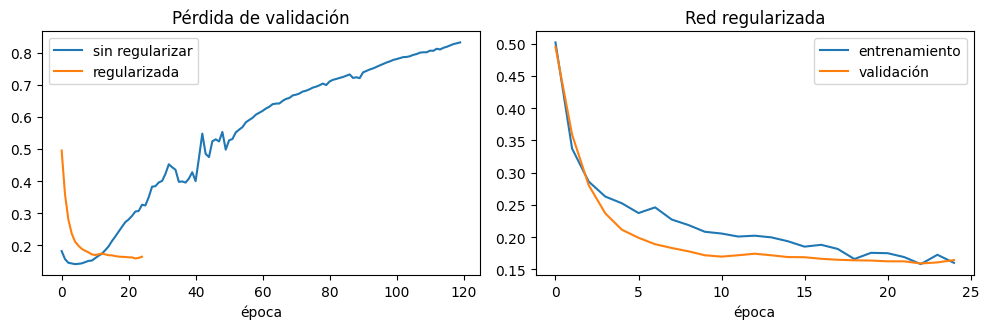

In [7]:
fig, ax = plt.subplots(1, 2)
ax[0].plot(h_grande.history['val_loss'], label='sin regularizar'); ax[0].plot(h_reg.history['val_loss'], label='regularizada')
ax[0].set_title('Pérdida de validación'); ax[0].set_xlabel('época'); ax[0].legend()
ax[1].plot(h_reg.history['loss'], label='entrenamiento'); ax[1].plot(h_reg.history['val_loss'], label='validación')
ax[1].set_title('Red regularizada'); ax[1].set_xlabel('época'); ax[1].legend(); plt.tight_layout(); plt.show()

### ➕ Ejemplo adicional: búsqueda pequeña de hiperparámetros

In [8]:
resultados = []
for lr in [1e-2, 1e-3]:
    for drop in [0.0, 0.3]:
        keras.utils.set_random_seed(42)
        m = keras.Sequential([keras.Input(shape=(len(cols),)), keras.layers.Dense(32, activation='relu'),
                              keras.layers.Dropout(drop), keras.layers.Dense(1, activation='sigmoid')])
        m.compile(optimizer=keras.optimizers.Adam(lr), loss='binary_crossentropy', metrics=[keras.metrics.AUC(name='auc')])
        h = m.fit(X_tr_esc, y_tr, validation_data=(X_val_esc, y_val), epochs=80, batch_size=32, verbose=0,
                  callbacks=[keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=10, restore_best_weights=True)])
        resultados.append({'learning_rate': lr, 'dropout': drop, 'épocas': len(h.history['loss']),
                           'AUC validación': round(max(h.history['val_auc']), 4)})
pd.DataFrame(resultados).sort_values('AUC validación', ascending=False)

,learning_rate,dropout,épocas,AUC validación
1,0.010,0.3,45,0.9724
2,0.001,0.0,80,0.9650
0,0.010,0.0,23,0.9595
3,0.001,0.3,47,0.9595


### 💬 Pregunta 1
En la red grande, ¿qué señal de las curvas indica sobreajuste? Si su modelo de fraude o de crédito del proyecto se sobreajusta, ¿qué dos técnicas aplicaría primero y por qué?

**Respuesta:**

En la red grande, la señal de sobreajuste es que la pérdida de entrenamiento sigue bajando, mientras que la pérdida de validación se estanca o empieza a subir; se abre una brecha entre ambas curvas. Si mi modelo de fraude o crédito se sobreajustara, aplicaría primero Dropout y EarlyStopping. Dropout obliga a la red a no depender de unas pocas neuronas y EarlyStopping evita seguir entrenando cuando la validación deja de mejorar, restaurando los mejores pesos. También podría añadir regularización L2.

---
## 5.2 Del laboratorio a producción (teoría · diapositivas)
Visión por computadora (CNN, detección con YOLO, transfer learning, mAP), tipos de redes, ML clásico en banca y ciclo de vida MLOps (feature store, registro de modelos, champion/challenger, drift, SHAP y equidad). **Sin código: siga las diapositivas.**

---
## 5.3 Detección de anomalías: Isolation Forest y LOF
Una **anomalía** es un caso raro respecto al resto (fraude, lavado, error de datos). No hay etiqueta: el modelo aprende qué es «normal».
- **Isolation Forest**: árboles con cortes al azar; un punto raro se **aísla con pocos cortes**.
- **LOF** (Local Outlier Factor): compara la **densidad** de un punto con la de sus vecinos.

Para **evaluar**, el curso sembró 15 cuentas anómalas conocidas (`sembrada = 1`); en la vida real no se tiene esa columna.

In [9]:
perfiles = curso.perfiles_clase5()                          # una fila por usuario
VARS = ['edad', 'ingreso_mensual', 'antiguedad_meses', 'n_transacciones', 'monto_medio',
        'pct_noche', 'pct_dispositivo_nuevo', 'distancia_media', 'intentos_medios']
X_perf = StandardScaler().fit_transform(perfiles[VARS])     # distancias y árboles comparables entre variables
perfiles[VARS + ['sembrada']].describe().round(2)

Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 8.44%
Perfiles: 788 usuarios · 15 anomalías sembradas (solo para evaluar)


,edad,ingreso_mensual,antiguedad_meses,n_transacciones,monto_medio,pct_noche,pct_dispositivo_nuevo,distancia_media,intentos_medios,sembrada
count,788.00,788.00,788.00,788.00,788.00,788.00,788.00,788.00,788.00,788.00
mean,43.85,925.74,29.86,4.03,92.04,0.11,0.16,6.30,1.27,0.02
std,14.90,438.83,17.68,2.18,103.74,0.19,0.22,4.71,0.38,0.14
min,18.00,221.95,1.00,1.00,6.45,0.00,0.00,0.00,1.00,0.00
25%,32.00,613.58,14.75,3.00,40.34,0.00,0.00,3.78,1.00,0.00
50%,44.00,832.02,29.00,4.00,64.36,0.00,0.00,5.44,1.00,0.00
75%,57.00,1133.75,45.00,5.00,105.79,0.20,0.25,7.39,1.50,0.00
max,70.00,3392.19,60.00,15.00,1026.47,1.00,1.00,50.70,3.00,1.00


### ✏️ Checkpoint 3 · ⏱ 4 min
Entrene un **Isolation Forest** con `contamination=0.03` y calcule qué proporción de las 15 cuentas sembradas detecta (**recall**, debe ser ≥ 0,8).

In [10]:
iso = IsolationForest(n_estimators=200, contamination=0.03, random_state=42).fit(X_perf)
perfiles['anomalo_if'] = iso.predict(X_perf) == -1
recall_if = perfiles.loc[perfiles['sembrada'] == 1, 'anomalo_if'].mean()
print(f"Marcados: {perfiles['anomalo_if'].sum()} · recall sobre sembradas: {recall_if:.2f}")
curso.checkpoint(3, recall_if)

Marcados: 24 · recall sobre sembradas: 1.00
Valor: 1 ≥ 0.8
✅ Checkpoint 3 correcto · código K3-522B


### ✏️ Checkpoint 4 · ⏱ 3 min
Aplique **LOF** con `n_neighbors=20` y la misma contaminación. Calcule su **recall** sobre las sembradas.

In [11]:
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.03)
perfiles['anomalo_lof'] = lof.fit_predict(X_perf) == -1
recall_lof = perfiles.loc[perfiles['sembrada'] == 1, 'anomalo_lof'].mean()
ambos = (perfiles['anomalo_if'] & perfiles['anomalo_lof']).sum()
print(f'Recall LOF: {recall_lof:.3f} · marcados por ambos métodos: {ambos}')
curso.checkpoint(4, recall_lof)

Recall LOF: 0.733 · marcados por ambos métodos: 18
✅ Checkpoint 4 correcto · código K4-049E


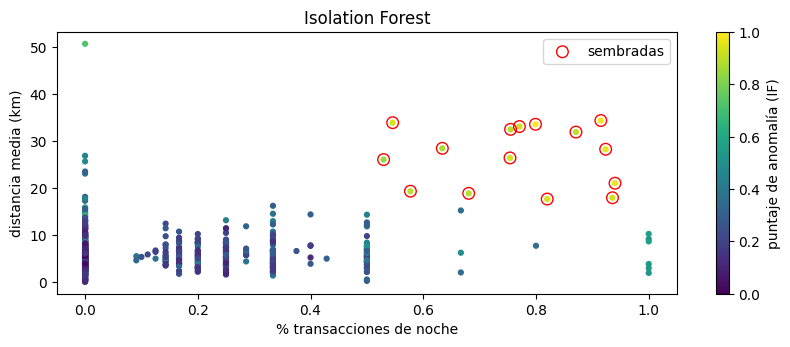

Tasa de usuarios con algún fraude · marcados: 0.375 · resto: 0.274


In [12]:
puntaje = -iso.score_samples(X_perf)                       # mayor = más anómalo
plt.scatter(perfiles['pct_noche'], perfiles['distancia_media'], c=puntaje, cmap='viridis', s=12)
s = perfiles['sembrada'] == 1
plt.scatter(perfiles.loc[s, 'pct_noche'], perfiles.loc[s, 'distancia_media'], facecolors='none', edgecolors='red', s=70, label='sembradas')
plt.colorbar(label='puntaje de anomalía (IF)'); plt.xlabel('% transacciones de noche'); plt.ylabel('distancia media (km)')
plt.legend(); plt.title('Isolation Forest'); plt.show()
print('Tasa de usuarios con algún fraude · marcados:', round((perfiles.loc[perfiles['anomalo_if'], 'fraudes'] > 0).mean(), 3),
      '· resto:', round((perfiles.loc[~perfiles['anomalo_if'], 'fraudes'] > 0).mean(), 3))

### ➕ Ejemplo adicional: autoencoder (anomalía = error de reconstrucción alto)

In [13]:
keras.utils.set_random_seed(42)
ae = keras.Sequential([keras.Input(shape=(len(VARS),)), keras.layers.Dense(6, activation='relu'),
                       keras.layers.Dense(3, activation='relu'),             # cuello de botella
                       keras.layers.Dense(6, activation='relu'), keras.layers.Dense(len(VARS))])
ae.compile(optimizer='adam', loss='mse')
limpios = X_perf[~perfiles['anomalo_if'].values]              # se entrena SOLO con lo que se considera normal
ae.fit(limpios, limpios, epochs=60, batch_size=32, verbose=0)   # aprende a copiar lo 'normal'
error = ((ae.predict(X_perf, verbose=0) - X_perf) ** 2).mean(axis=1)
top = error >= np.quantile(error, 0.97)
print(f"Recall del autoencoder (top 3 %): {perfiles.loc[top, 'sembrada'].sum() / 15:.2f}")

Recall del autoencoder (top 3 %): 1.00


---
## 5.4 Segmentación económica: K-Means, PCA y DBSCAN
Primero se **retiran las anomalías** (distorsionan los centroides). Luego se segmenta con variables de **comportamiento**; el ingreso y el monto se pasan a logaritmo (son muy asimétricos).

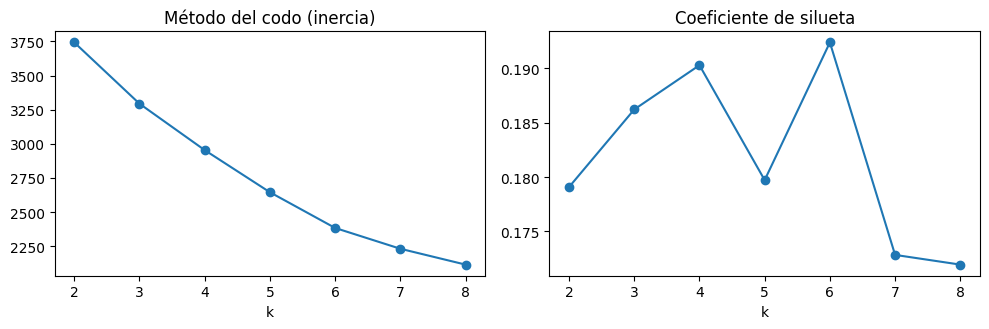

In [14]:
seg = perfiles.loc[~perfiles['anomalo_if']].copy()            # sin anomalías
VSEG = ['ingreso_mensual', 'n_transacciones', 'monto_medio', 'pct_noche', 'pct_dispositivo_nuevo', 'distancia_media']
Z = seg[VSEG].copy()
Z[['ingreso_mensual', 'monto_medio']] = np.log(Z[['ingreso_mensual', 'monto_medio']])
X_seg = StandardScaler().fit_transform(Z)
inercias, siluetas = [], []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_seg)
    inercias.append(km.inertia_); siluetas.append(silhouette_score(X_seg, km.labels_))
fig, ax = plt.subplots(1, 2)
ax[0].plot(range(2, 9), inercias, 'o-'); ax[0].set_title('Método del codo (inercia)'); ax[0].set_xlabel('k')
ax[1].plot(range(2, 9), siluetas, 'o-'); ax[1].set_title('Coeficiente de silueta'); ax[1].set_xlabel('k')
plt.tight_layout(); plt.show()

### ✏️ Checkpoint 5 · ⏱ 4 min
Ajuste **K-Means con k = 4** y calcule el **coeficiente de silueta**.

In [15]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_seg)
seg['segmento'] = km4.labels_
sil = silhouette_score(X_seg, km4.labels_)
print(f'Silueta k=4: {sil:.3f}')
curso.checkpoint(5, sil)

Silueta k=4: 0.190
✅ Checkpoint 5 correcto · código K5-29F9


In [16]:
perfil = seg.groupby('segmento')[VSEG + ['fraudes']].mean().round(2)
perfil['usuarios'] = seg['segmento'].value_counts().sort_index()
perfil

,ingreso_mensual,n_transacciones,monto_medio,pct_noche,pct_dispositivo_nuevo,distancia_media,fraudes,usuarios
segmento,,,,,,,,
0,796.50,3.04,61.65,0.05,0.51,6.50,0.51,98
1,622.76,3.68,43.74,0.02,0.06,5.45,0.17,266
2,834.22,3.14,74.31,0.42,0.10,6.17,0.36,107
3,1252.89,4.66,120.49,0.06,0.12,5.84,0.39,293


**Leer los segmentos** (ponerles nombre y una acción): compare cada fila con el promedio. Ejemplo de lectura: *ingreso bajo y montos pequeños* → «básico» (educación financiera); *ingreso y montos altos, más transacciones* → «activo de alto valor» (productos premium); *alto % nocturno* → «nocturno» (monitoreo reforzado); *alto % de dispositivo nuevo* → «multidispositivo» (verificación de identidad).

### ✏️ Checkpoint 6 · ⏱ 3 min
Reduzca a **2 componentes principales** y calcule la **varianza explicada acumulada**.

In [17]:
pca = PCA(n_components=2).fit(X_seg)
var2 = pca.explained_variance_ratio_.sum()
print(f'Varianza explicada por 2 componentes: {var2:.3f}')
curso.checkpoint(6, var2)

Varianza explicada por 2 componentes: 0.461
✅ Checkpoint 6 correcto · código K6-6773


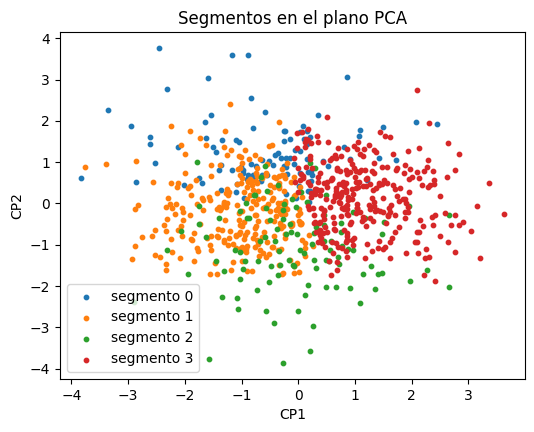

,CP1,CP2
ingreso_mensual,0.68,-0.05
n_transacciones,0.19,0.45
monto_medio,0.70,0.01
pct_noche,0.08,-0.40
pct_dispositivo_nuevo,-0.02,0.67
distancia_media,-0.04,0.43


In [18]:
P = pca.transform(X_seg)
plt.figure(figsize=(6, 4.5))
for s_ in sorted(seg['segmento'].unique()):
    m = seg['segmento'].values == s_
    plt.scatter(P[m, 0], P[m, 1], s=10, label=f'segmento {s_}')
plt.xlabel('CP1'); plt.ylabel('CP2'); plt.legend(); plt.title('Segmentos en el plano PCA'); plt.show()
pd.DataFrame(pca.components_.T, index=VSEG, columns=['CP1', 'CP2']).round(2)

### DBSCAN: grupos por densidad (no hay que fijar k)
`eps` = radio de vecindad; `min_samples` = vecinos mínimos para ser núcleo. Los puntos que no pertenecen a ninguna zona densa quedan como **ruido (−1)**. El gráfico de la distancia al k-ésimo vecino ayuda a elegir `eps` (el «codo»).

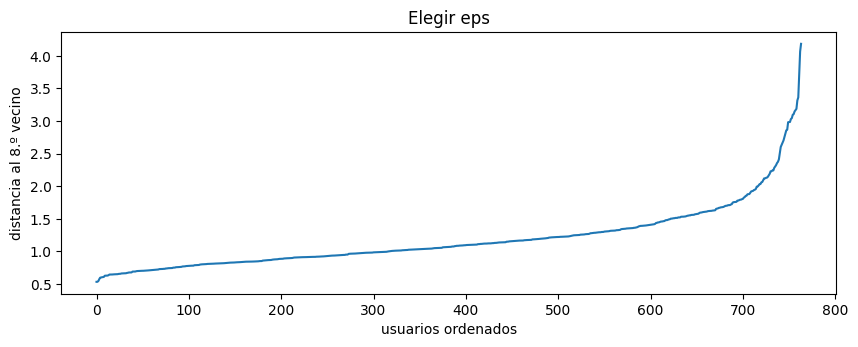

eps=1.0: 4 grupos · ruido = 286 usuarios
eps=1.2: 1 grupos · ruido = 144 usuarios
eps=1.4: 1 grupos · ruido = 69 usuarios


In [19]:
dist = np.sort(NearestNeighbors(n_neighbors=8).fit(X_seg).kneighbors(X_seg)[0][:, -1])
plt.plot(dist); plt.ylabel('distancia al 8.º vecino'); plt.xlabel('usuarios ordenados'); plt.title('Elegir eps'); plt.show()
for eps in [1.0, 1.2, 1.4]:
    etiquetas = DBSCAN(eps=eps, min_samples=8).fit_predict(X_seg)
    grupos = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
    print(f'eps={eps}: {grupos} grupos · ruido = {(etiquetas == -1).sum()} usuarios')

### ➕ Ejemplo adicional: clustering jerárquico (dendrograma)

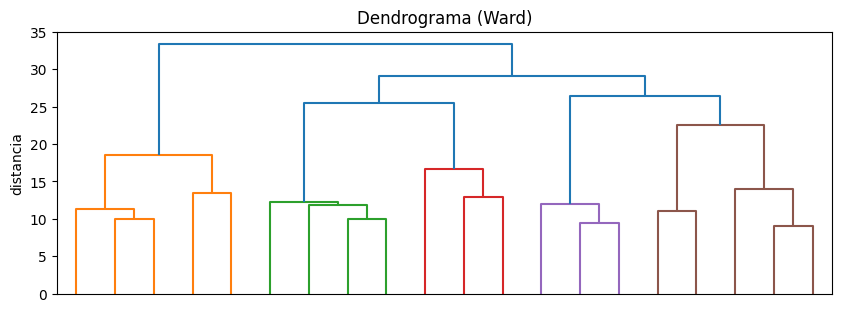

In [20]:
from scipy.cluster.hierarchy import linkage, dendrogram
enlaces = linkage(X_seg, method='ward')
dendrogram(enlaces, truncate_mode='lastp', p=20, no_labels=True); plt.title('Dendrograma (Ward)'); plt.ylabel('distancia'); plt.show()

### 💬 Pregunta 2
Elija uno de los 4 segmentos que obtuvo: póngale un nombre y proponga una acción de negocio para PagoYa. ¿Por qué conviene retirar las anomalías antes de segmentar?

**Respuesta:**

si un segmento tiene ingreso y monto medio-altos, muchas transacciones y bajo porcentaje nocturno, lo llamaría “cliente activo de alto valor”. Acción para PagoYa: ofrecerle productos premium, mayores límites y beneficios por fidelidad, con monitoreo normal. Conviene retirar las anomalías antes de segmentar porque los valores extremos distorsionan los centroides y las distancias: K-Means y PCA pueden quedar “tirados” hacia casos raros que no representan al cliente normal. Las anomalías deben analizarse aparte, no mezclarse con la segmentación comercial.

---
## 5.5 IA generativa, agentes y gobierno de IA en banca (teoría · diapositivas)
Escalera de decisión (reglas → prompt → RAG → agente → fine-tuning), RAG, agentes y MCP, evaluación (golden set, LLM-as-judge), riesgos y controles, plataforma de IA con *AI Gateway* y marcos de gobierno (LOPDP, NIST AI RMF, ISO/IEC 42001, AI Act). **Sin código: siga las diapositivas.**

### 💬 Pregunta 3
Para un banco, dé un ejemplo de problema que resolvería con **ML clásico**, uno con **RAG** y uno con un **agente**. ¿Qué control pondría en el caso del agente?

**Respuesta:**

ML clásico: scoring de crédito o detección de fraude con gradient boosting, usando variables transaccionales e historial.

RAG: un asistente interno que responda dudas sobre políticas, normativa y productos bancarios consultando una base documental actualizada.

Agente: un agente que gestione disputas o solicitudes de reembolso, consulte sistemas y prepare la acción.

Control para el agente: aprobación humana para acciones sensibles, límites de monto, permisos mínimos, registro/auditoría de cada paso y posibilidad de detenerlo. Nunca debería ejecutar movimientos de dinero sin validación humana y trazabilidad.

---
## Cierre
- Hoy: regularización en redes, detección de anomalías (Isolation Forest, LOF), segmentación (K-Means, PCA, DBSCAN) y la arquitectura para llevar IA a producción.
- **Proyecto:** grupos de **segmentación**, repliquen 5.3 y 5.4 con `curso.datos_proyecto(GRUPO, 'segmentacion')`. Grupos de **fraude/crédito**, pueden sumar una red regularizada (5.1) como familia de modelos. Repositorio hasta el **miércoles 18-nov, 23:59**.

In [21]:
curso.resumen()

Estudiante: Verdezoto Marcelo · checkpoints correctos: 7/7
Pendientes: ninguno ✅
👉 Responda las preguntas 💬 y guarde: Archivo → Guardar (Ctrl+S) → su repositorio (hasta las 12:00 del día siguiente sin descuento).
